Import modules & data loading

In [16]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from datetime import timedelta

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.figsize"] = (12, 5)
pd.set_option("display.float_format", lambda x: f"{x:,.3f}")

df = pd.read_csv("train.csv",
                 parse_dates=["pickup_datetime", "dropoff_datetime"])

print("Raw shape:", df.shape)
print(df.dtypes)
df.head()

Raw shape: (1458644, 11)
id                            object
vendor_id                      int64
pickup_datetime       datetime64[ns]
dropoff_datetime      datetime64[ns]
passenger_count                int64
pickup_longitude             float64
pickup_latitude              float64
dropoff_longitude            float64
dropoff_latitude             float64
store_and_fwd_flag            object
trip_duration                  int64
dtype: object


,id,vendor_id,pickup_datetime,dropoff_datetime,passenger_count,pickup_longitude,pickup_latitude,dropoff_longitude,dropoff_latitude,store_and_fwd_flag,trip_duration
0,id2875421,2,2016-03-14 17:24:55,2016-03-14 17:32:30,1,-73.982,40.768,-73.965,40.766,N,455
1,id2377394,1,2016-06-12 00:43:35,2016-06-12 00:54:38,1,-73.980,40.739,-73.999,40.731,N,663
2,id3858529,2,2016-01-19 11:35:24,2016-01-19 12:10:48,1,-73.979,40.764,-74.005,40.710,N,2124
3,id3504673,2,2016-04-06 19:32:31,2016-04-06 19:39:40,1,-74.010,40.720,-74.012,40.707,N,429
4,id2181028,2,2016-03-26 13:30:55,2016-03-26 13:38:10,1,-73.973,40.793,-73.973,40.783,N,435


Data cleaning

In [18]:

#Data cleaning
def haversine_np(lon1, lat1, lon2, lat2):
    """Great-circle distance in km between two points (decimal degrees)."""
    lon1, lat1, lon2, lat2 = map(np.radians, [lon1, lat1, lon2, lat2])
    dlon = lon2 - lon1
    dlat = lat2 - lat1
    a = np.sin(dlat / 2.0) ** 2 + np.cos(lat1) * np.cos(lat2) * np.sin(dlon / 2.0) ** 2
    c = 2 * np.arcsin(np.sqrt(a))
    return 6367 * c

#Pre-cleaning diagnostics
df["distance_km"] = haversine_np(df.pickup_longitude, df.pickup_latitude,
                                 df.dropoff_longitude, df.dropoff_latitude)
df["speed_kmh"] = df["distance_km"] / (df["trip_duration"] / 3600)

print(df[["trip_duration", "distance_km", "speed_kmh"]].describe(percentiles=[.01, .5, .99]))
print("\nNegative/zero durations:", (df.trip_duration <= 0).sum())
print("Durations > 6 h     :", (df.trip_duration > 6 * 3600).sum())
print("Zero-distance trips :", (df.distance_km == 0).sum())
print("Speed > 100 km/h    :", (df.speed_kmh > 100).sum())
print("Speed < 1 km/h      :", (df.speed_kmh < 1).sum())
print("Pickup outside NYC  :",
      ((~df.pickup_longitude.between(-74.3, -73.7)) |
       (~df.pickup_latitude.between(40.5, 41.0))).sum())
print("\npassenger_count distribution:\n", df.passenger_count.value_counts().sort_index())

#Show the effect of each filter
def summarize(name, mask):
    kept = mask.sum()
    print(f"{name:<38} kept {kept:>10,}  ({kept/len(df)*100:5.2f}%)")
    return mask

# 1. sensible duration: between 30 s and 6 h
m_dur  = df.trip_duration.between(30, 6 * 3600)
# 2. plausible average speed: between 1 and 100 km/h
m_spd  = df.speed_kmh.between(1, 100)
# 3. pickup and dropoff inside the NYC bounding box
m_box  = (df.pickup_longitude.between(-74.3, -73.7) &
          df.pickup_latitude .between(40.5, 41.0) &
          df.dropoff_longitude.between(-74.3, -73.7) &
          df.dropoff_latitude .between(40.5, 41.0))
# 4. non-zero distance (removes cancelled / GPS-stuck trips)
m_dist = df.distance_km > 0
# 5. valid passenger count
m_pass = df.passenger_count.between(1, 6)

print("\n--- Filter retention ---")
summarize("Duration 30 s – 6 h", m_dur)
summarize("Speed 1 – 100 km/h", m_spd)
summarize("Coordinates in NYC bbox", m_box)
summarize("Distance > 0", m_dist)
summarize("Passenger count 1–6", m_pass)

mask = m_dur & m_spd & m_box & m_dist & m_pass
df_clean = df.loc[mask].copy()

print("\nRows before cleaning:", f"{len(df):,}")
print("Rows after  cleaning:", f"{len(df_clean):,}",
      f"({len(df_clean)/len(df)*100:.2f}% retained)")

print("\nCleaned summary:")
print(df_clean[["trip_duration", "distance_km", "speed_kmh"]].describe())

       trip_duration   distance_km     speed_kmh
count  1,458,644.000 1,458,644.000 1,458,644.000
mean         959.492         3.439        14.414
std        5,237.432         4.294        14.968
min            1.000         0.000         0.000
1%            87.000         0.139         1.393
50%          662.000         2.092        12.784
99%        3,440.000        20.774        40.720
max    3,526,282.000     1,240.130     9,269.014

Negative/zero durations: 0
Durations > 6 h     : 2061
Zero-distance trips : 5897
Speed > 100 km/h    : 175
Speed < 1 km/h      : 13241
Pickup outside NYC  : 256

passenger_count distribution:
 passenger_count
0         60
1    1033540
2     210318
3      59896
4      28404
5      78088
6      48333
7          3
8          1
9          1
Name: count, dtype: int64

--- Filter retention ---
Duration 30 s – 6 h                    kept  1,451,801  (99.53%)
Speed 1 – 100 km/h                     kept  1,445,228  (99.08%)
Coordinates in NYC bbox              

Feature Generation

In [19]:

df_clean["pickup_date"]   = df_clean.pickup_datetime.dt.date
df_clean["pickup_hour"]   = df_clean.pickup_datetime.dt.hour
df_clean["pickup_dow"]    = df_clean.pickup_datetime.dt.dayofweek          # Mon=0 … Sun=6
df_clean["day_name"]      = df_clean.pickup_datetime.dt.day_name()
df_clean["is_weekend"]    = df_clean.pickup_dow >= 5
# (distance_km and speed_kmh were created before cleaning in Cell 1)

# sanity check
print(df_clean[["pickup_datetime","distance_km","trip_duration",
                "speed_kmh","pickup_dow","day_name","pickup_hour"]].head())

print("\nDay-of-week counts:")
print(df_clean.day_name.value_counts().reindex(
    ["Monday","Tuesday","Wednesday","Thursday","Friday","Saturday","Sunday"]))

      pickup_datetime  distance_km  trip_duration  speed_kmh  pickup_dow  \
0 2016-03-14 17:24:55        1.498            455     11.849           0   
1 2016-06-12 00:43:35        1.804            663      9.798           6   
2 2016-01-19 11:35:24        6.381           2124     10.815           1   
3 2016-04-06 19:32:31        1.485            429     12.458           2   
4 2016-03-26 13:30:55        1.188            435      9.830           5   

    day_name  pickup_hour  
0     Monday           17  
1     Sunday            0  
2    Tuesday           11  
3  Wednesday           19  
4   Saturday           13  

Day-of-week counts:
day_name
Monday       185308
Tuesday      200459
Wednesday    207871
Thursday     216049
Friday       220968
Saturday     218393
Sunday       192983
Name: count, dtype: int64


Q3.1: Which day of the week is the most popular?

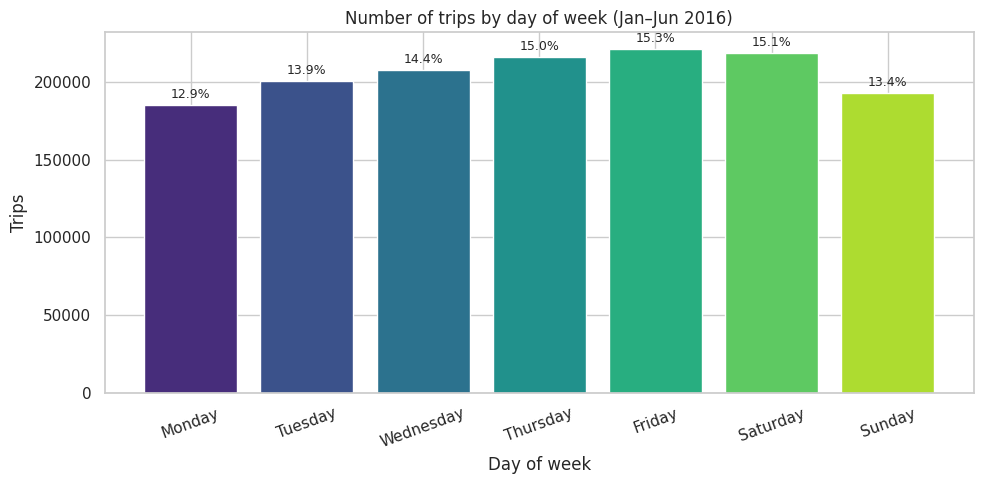

            trips  share_pct
day_name                    
Monday     185308     12.850
Tuesday    200459     13.901
Wednesday  207871     14.415
Thursday   216049     14.982
Friday     220968     15.323
Saturday   218393     15.145
Sunday     192983     13.383

Most popular day: Friday (220,968 trips)
Least popular day: Monday (185,308 trips)


In [20]:

order = ["Monday","Tuesday","Wednesday","Thursday","Friday","Saturday","Sunday"]
counts = df_clean.day_name.value_counts().reindex(order)
share  = counts / counts.sum() * 100

fig, ax = plt.subplots(figsize=(10, 5))
bars = ax.bar(order, counts.values, color=sns.color_palette("viridis", 7))
ax.bar_label(bars, labels=[f"{s:.1f}%" for s in share], padding=3, fontsize=9)
ax.set_title("Number of trips by day of week (Jan–Jun 2016)")
ax.set_ylabel("Trips")
ax.set_xlabel("Day of week")
plt.xticks(rotation=20)
plt.tight_layout(); plt.savefig("q3_1_day_of_week.png", dpi=150); plt.show()

print(counts.to_frame("trips").assign(share_pct=share))
print("\nMost popular day:", counts.idxmax(), f"({counts.max():,} trips)")
print("Least popular day:", counts.idxmin(), f"({counts.min():,} trips)")

Q3.2: Most popular hour on each day

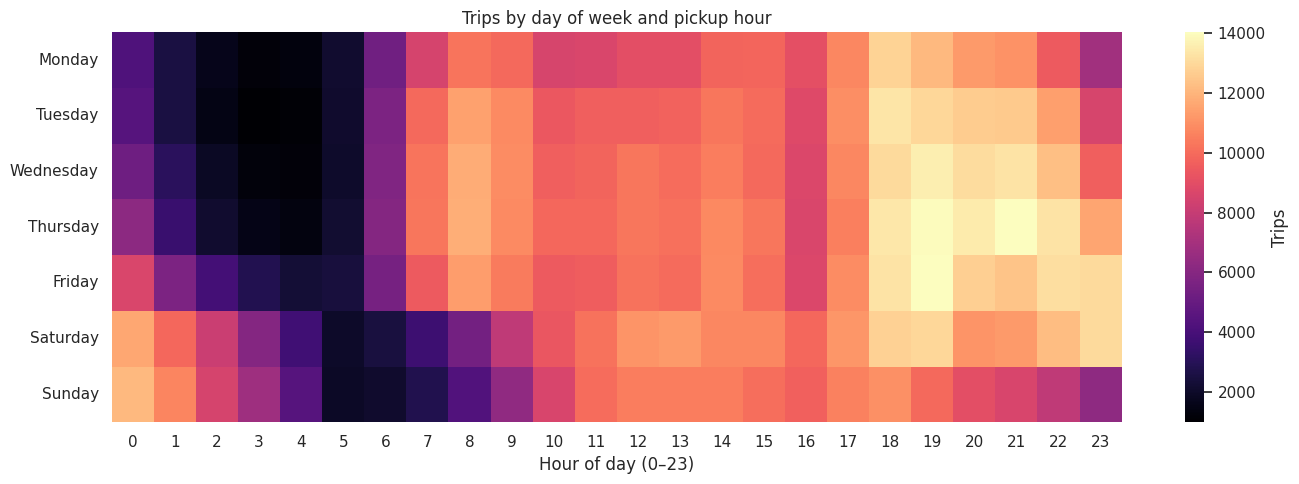

Peak hour per day:
 day_name
Monday       18
Tuesday      18
Wednesday    19
Thursday     21
Friday       19
Saturday     23
Sunday        0

Peak trip count per day:
 day_name
Monday       12829
Tuesday      13328
Wednesday    13573
Thursday     14019
Friday       14030
Saturday     13051
Sunday       12143


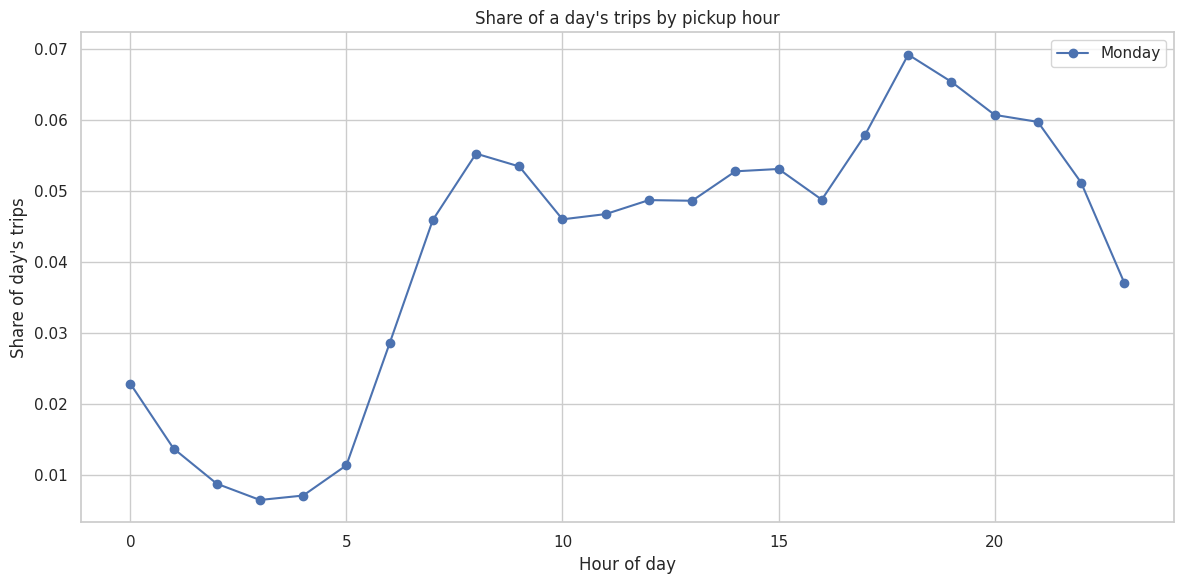

<Figure size 1200x500 with 0 Axes>

<Figure size 1200x500 with 0 Axes>

<Figure size 1200x500 with 0 Axes>

<Figure size 1200x500 with 0 Axes>

<Figure size 1200x500 with 0 Axes>

<Figure size 1200x500 with 0 Axes>

In [21]:

hour_day = (df_clean.groupby(["day_name","pickup_hour"])
                      .size()
                      .unstack("pickup_hour")
                      .reindex(order))

fig, ax = plt.subplots(figsize=(14, 5))
sns.heatmap(hour_day, cmap="magma", ax=ax, cbar_kws={"label": "Trips"})
ax.set_title("Trips by day of week and pickup hour")
ax.set_xlabel("Hour of day (0–23)"); ax.set_ylabel("")
plt.tight_layout(); plt.savefig("q3_2_heatmap.png", dpi=150); plt.show()

peak = hour_day.idxmax(axis=1)
print("Peak hour per day:\n", peak.to_string())
print("\nPeak trip count per day:\n", hour_day.max(axis=1).to_string())

# A second, clearer view: normalised hourly profile per day
profiles = hour_day.div(hour_day.sum(axis=1), axis=0)
fig, ax = plt.subplots(figsize=(12, 6))
for day in order:
    ax.plot(profiles.columns, profiles.loc[day], marker="o", label=day)
    ax.set_title("Share of a day's trips by pickup hour")
    ax.set_xlabel("Hour of day"); ax.set_ylabel("Share of day's trips")
    ax.legend(ncol=4); plt.tight_layout()
    plt.savefig("q3_2_profiles.png", dpi=150); plt.show()

Q3.3: Weekday vs weekend

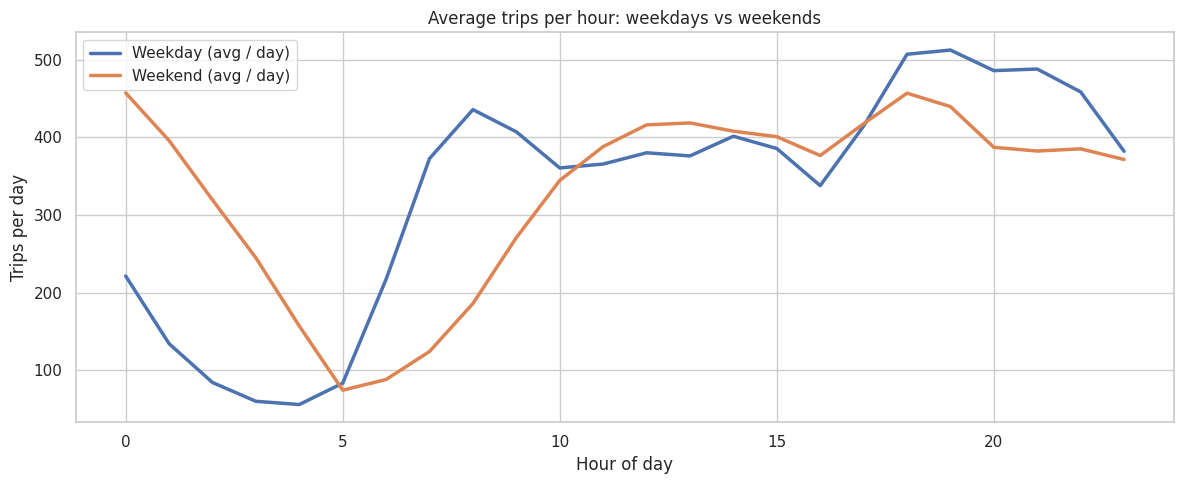

Weekday peak hour: 19 (512 trips/day)
Weekend peak hour: 0 (457 trips/day)


In [22]:

weekday_hours = (df_clean[~df_clean.is_weekend]
                 .groupby("pickup_hour").size())
weekend_hours = (df_clean[ df_clean.is_weekend]
                 .groupby("pickup_hour").size())

# Normalise to average trips per day so the two curves are comparable
n_week_days   = df_clean.loc[~df_clean.is_weekend, "pickup_date"].nunique()
n_weekend_days= df_clean.loc[ df_clean.is_weekend, "pickup_date"].nunique()
weekday_avg = weekday_hours / n_week_days
weekend_avg = weekend_hours / n_weekend_days

fig, ax = plt.subplots(figsize=(12, 5))
ax.plot(weekday_avg.index, weekday_avg.values, lw=2.5, label="Weekday (avg / day)")
ax.plot(weekend_avg.index, weekend_avg.values, lw=2.5, label="Weekend (avg / day)")
ax.set_title("Average trips per hour: weekdays vs weekends")
ax.set_xlabel("Hour of day"); ax.set_ylabel("Trips per day")
ax.legend(); plt.tight_layout()
plt.savefig("q3_3_weekday_vs_weekend.png", dpi=150); plt.show()

print("Weekday peak hour:", int(weekday_avg.idxmax()),
      f"({weekday_avg.max():,.0f} trips/day)")
print("Weekend peak hour:", int(weekend_avg.idxmax()),
      f"({weekend_avg.max():,.0f} trips/day)")

Q3.4: Major holidays

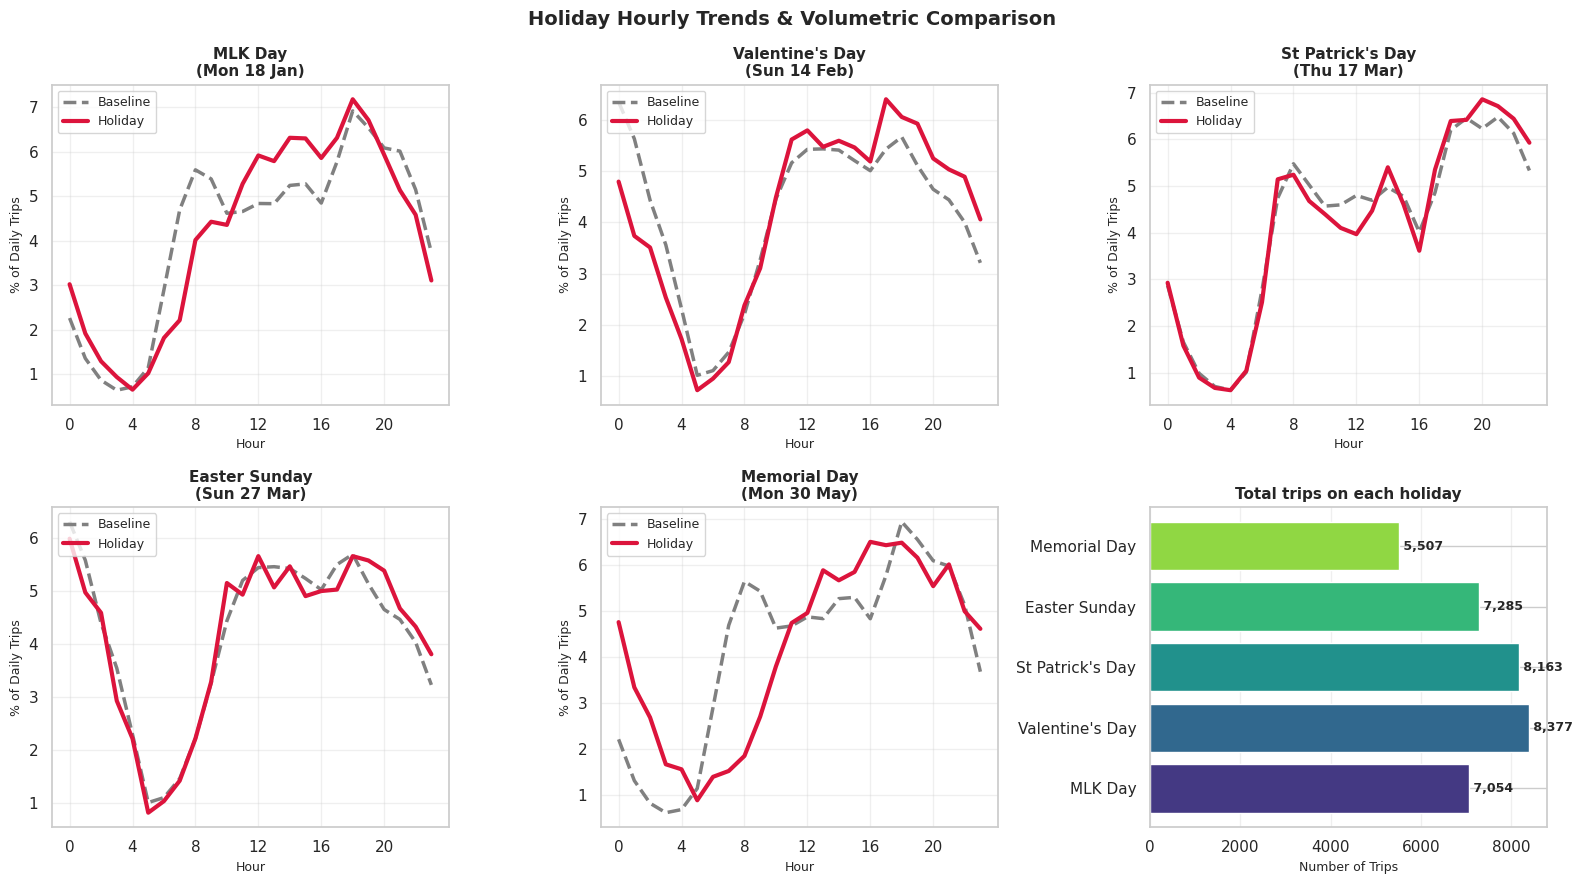

In [23]:
holidays = {
    "MLK Day\n(Mon 18 Jan)":              "2016-01-18",
    "Valentine's Day\n(Sun 14 Feb)":      "2016-02-14",
    "St Patrick's Day\n(Thu 17 Mar)":     "2016-03-17",
    "Easter Sunday\n(Sun 27 Mar)":        "2016-03-27",
    "Memorial Day\n(Mon 30 May)":         "2016-05-30",
}

def hourly_profile_for_date(frame, day):
    d = frame[frame.pickup_date == pd.Timestamp(day).date()]
    counts = d.groupby("pickup_hour").size().reindex(range(24), fill_value=0)
    return counts / counts.sum() if counts.sum() > 0 else counts

def baseline_for_weekday(frame, day):
    dow = pd.Timestamp(day).dayofweek
    other = frame[(frame.pickup_dow == dow) &
                  (frame.pickup_date != pd.Timestamp(day).date())]
    per_day = other.groupby(["pickup_date","pickup_hour"]).size().unstack(fill_value=0)
    mean_profile = per_day.mean(axis=0).reindex(range(24), fill_value=0)
    return mean_profile / mean_profile.sum() if mean_profile.sum() > 0 else mean_profile

# Set up a 2x3 grid. Subplots 1-5 show the hourly curves.
fig, axes = plt.subplots(2, 3, figsize=(16, 9))
axes = axes.ravel()

for idx, (label, day) in enumerate(holidays.items()):
    ax = axes[idx]
    hol = hourly_profile_for_date(df_clean, day) * 100
    base = baseline_for_weekday(df_clean, day) * 100

    # Plot clean line profiles (without background bar charts)
    ax.plot(range(24), base.values, lw=2.5, label="Baseline", color="grey", linestyle="--")
    ax.plot(range(24), hol.values,  lw=3, label="Holiday", color="crimson")

    ax.set_title(label, fontsize=11, fontweight='bold')
    ax.set_xlabel("Hour", fontsize=9)
    ax.set_ylabel("% of Daily Trips", fontsize=9)
    ax.set_xticks(range(0, 24, 4))
    ax.grid(True, alpha=0.3)
    ax.legend(fontsize=9, loc="upper left")

# 6th cell: total volume comparison bar chart
ax = axes[-1]
tot = {label.split("\n")[0]: df_clean[df_clean.pickup_date == pd.Timestamp(day).date()].shape[0]
       for label, day in holidays.items()}

bars = ax.barh(list(tot.keys()), list(tot.values()), color=sns.color_palette("viridis", len(tot)))
ax.set_title("Total trips on each holiday", fontsize=11, fontweight='bold')
ax.set_xlabel("Number of Trips", fontsize=9)
ax.grid(True, axis='x', alpha=0.3)

# Add values next to the bars
for bar in bars:
    width = bar.get_width()
    ax.text(width, bar.get_y() + bar.get_height()/2, f" {int(width):,}",
            va='center', ha='left', fontsize=9, fontweight='bold')

plt.suptitle("Holiday Hourly Trends & Volumetric Comparison", y=0.98, fontsize=14, fontweight='bold')
plt.tight_layout()
plt.savefig("q3_4_holidays.png", dpi=150)
plt.show()

Q3.5: Average speed by hour of day

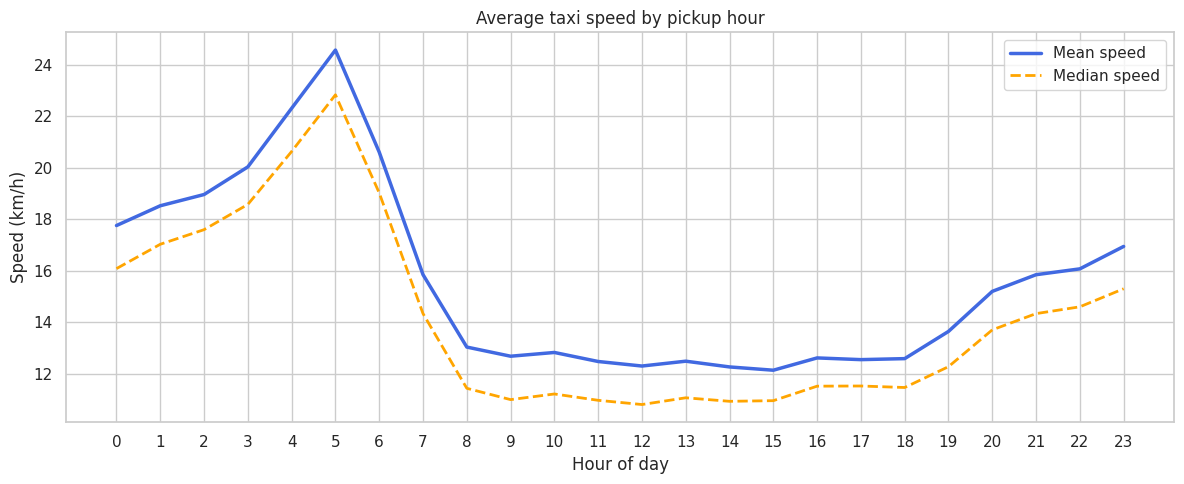

              mean  median  count
pickup_hour                      
0           17.760  16.090  52571
1           18.530  17.030  38060
2           18.960  17.600  27597
3           20.040  18.580  20571
4           22.310  20.630  15472
5           24.570  22.830  14752
6           20.610  19.030  32863
7           15.850  14.340  54915
8           13.040  11.440  66312
9           12.680  11.000  67005
10          12.830  11.220  64787
11          12.480  10.970  67707
12          12.300  10.810  71043
13          12.490  11.070  70650
14          12.270  10.930  73387
15          12.140  10.960  70965
16          12.620  11.520  63494
17          12.550  11.530  75592
18          12.590  11.470  89650
19          13.650  12.280  89450
20          15.200  13.710  83286
21          15.850  14.340  83303
22          16.080  14.600  79621
23          16.950  15.300  68978

Fastest hour (mean): 5 (24.6 km/h)
Slowest hour (mean): 15 (12.1 km/h)


In [24]:
speed_by_hour = (df_clean.groupby("pickup_hour")["speed_kmh"]
                 .agg(["mean", "median", "count"]))

fig, ax = plt.subplots(figsize=(12, 5))
ax.plot(speed_by_hour.index, speed_by_hour["mean"], lw=2.5, label="Mean speed", color="royalblue")
ax.plot(speed_by_hour.index, speed_by_hour["median"], lw=2, ls="--", label="Median speed", color="orange")
ax.set_title("Average taxi speed by pickup hour")
ax.set_xlabel("Hour of day")
ax.set_ylabel("Speed (km/h)")
ax.set_xticks(range(24))
ax.legend()
plt.tight_layout()
plt.savefig("q3_5_speed_by_hour.png", dpi=150)
plt.show()

print(speed_by_hour.round(2))
print("\nFastest hour (mean):", int(speed_by_hour["mean"].idxmax()),
      f"({speed_by_hour['mean'].max():.1f} km/h)")
print("Slowest hour (mean):", int(speed_by_hour["mean"].idxmin()),
      f"({speed_by_hour['mean'].min():.1f} km/h)")